# Laboratorio 3 - La tarea de clasificación: Ruta Alpes

**Integrantes:** Andres Mateo Jurado Caceres

En este notebook se desarrollan los puntos 1 a 7 del laboratorio y la generación del archivo de predicciones (`Lab3_datos_Prueba.csv`) para los cupones **Cafetería** y **Restaurante(<20)**.

> Requiere las librerías `pandas`, `openpyxl`, `scikit-learn`, `imbalanced-learn`, `matplotlib` y `seaborn`.

## 0. Librerías y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,f1_score, recall_score, precision_score)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

In [2]:
from importlib.metadata import version
print(f"Versión de Pandas: {version('pandas')}")
print(f"Versión de Scikit learn: {version('scikit-learn')}")
print(f"Versión de imbalanced-learn: {version('imbalanced-learn')}")

Versión de Pandas: 3.0.6
Versión de Scikit learn: 1.7.2
Versión de imbalanced-learn: 0.14.0


In [3]:
datos_cupones = pd.read_excel('./Data/Lab3_Datos.xlsx')
data = datos_cupones.copy()
data.shape

(12664, 26)

In [4]:
dict = pd.read_excel('./Data/Lab3_diccionario_Datos.xlsx')
pd.set_option('display.max_colwidth', None)
dict

,Variable,Tipo,Descripción
0,destino,Categórica nominal,"Destino del trayecto en el momento en que se ofrece el cupón. Valores posibles: Casa, Sin lugar urgente, Trabajo."
1,acompanante,Categórica nominal,"Tipo de acompañante(s) en el vehículo al momento de la oferta. Valores posibles: Solo, Amigo(s), Hijo(s), Pareja."
2,clima,Categórica nominal,"Condición climática durante el trayecto. Valores posibles: Soleado, Lluvioso, Nevado."
3,temperatura,Numérica entero,"Temperatura ambiente en grados Fahrenheit. Variable de diseño de la encuesta: solo toma 3 valores fijos, asociados al clima. Rango: {30, 55, 80}."
4,hora,Categórica ordinal,"Hora del día en que ocurre el trayecto. Valores posibles (en orden): 7:00 a.m., 10:00 a.m., 2:00 p.m., 6:00 p.m., 10:00 p.m."
5,cupon,Categórica nominal,"Tipo de cupón ofrecido al conductor. Valores posibles: Bar, Cafetería, Comida para llevar, Restaurante(<20), Restaurante(20-50). Los valores <20 y 20-50 indican los gastos pormedios por persona para estos cupones."
6,vigencia_cupon,Categórica nominal,"Tiempo de vigencia del cupón antes de expirar. Valores posibles: 2 horas, 1 día."
7,genero,Categórica nominal,"Género reportado por el conductor. Valores posibles: Femenino, Masculino."
8,edad,Categórica ordinal,"Rango de edad del conductor. Valores posibles (en orden): menor de 21, 21, 26, 31, 36, 41, 46, 50 o más."
9,estado_civil,Categórica nominal,"Estado civil del conductor. Valores posibles: Soltero(a), Casado(a), Unión libre, Divorciado(a), Viudo(a)."


In [5]:
data.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


## 1. Exploración de los datos

Primero se revisa el conjunto completo y luego cada subconjunto (Cafetería y Restaurante(<20)), que es con lo que se van a construir los modelos.

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12664 entries, 0 to 12663
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   destino                          12664 non-null  str  
 1   acompanante                      12664 non-null  str  
 2   clima                            12664 non-null  str  
 3   temperatura                      12664 non-null  int64
 4   hora                             12664 non-null  str  
 5   cupon                            12664 non-null  str  
 6   vigencia_cupon                   12664 non-null  str  
 7   genero                           12664 non-null  str  
 8   edad                             12664 non-null  str  
 9   estado_civil                     12664 non-null  str  
 10  tiene_hijos                      12664 non-null  str  
 11  educacion                        12664 non-null  str  
 12  ocupacion                        12664 non-null  str  
 1

In [7]:
data['cupon'].value_counts()

cupon
Cafetería             3986
Restaurante(<20)      2776
Comida para llevar    2393
Bar                   2017
Restaurante(20-50)    1492
Name: count, dtype: int64

In [8]:
# Subconjuntos de interés
data_cafe = data[data['cupon'] == 'Cafetería'].copy()
data_rest = data[data['cupon'] == 'Restaurante(<20)'].copy()

print(f"Cafetería:        {data_cafe.shape}")
print(f"Restaurante(<20): {data_rest.shape}")

Cafetería:        (3986, 26)
Restaurante(<20): (2776, 26)


### 1.1 Completitud (valores nulos)

In [9]:
nulos = pd.DataFrame({
    'Cafetería (%)': (data_cafe.isnull().sum() / data_cafe.shape[0] * 100).round(2),
    'Restaurante(<20) (%)': (data_rest.isnull().sum() / data_rest.shape[0] * 100).round(2)
})
nulos[nulos.sum(axis=1) > 0].sort_values(by='Cafetería (%)', ascending=False)

,Cafetería (%),Restaurante(<20) (%)
vehiculo,99.07,99.10
frecuencia_cafeteria,1.81,1.69
frecuencia_comida_para_llevar,1.43,1.22
frecuencia_restaurante_20_a_50,1.38,1.55
frecuencia_restaurante_menos_20,1.25,0.97
frecuencia_bar,0.93,0.83


### 1.2 Unicidad (registros duplicados)

In [10]:
print(f"Duplicados en Cafetería:        {data_cafe.duplicated().sum()}")
print(f"Duplicados en Restaurante(<20): {data_rest.duplicated().sum()}")

Duplicados en Cafetería:        7
Duplicados en Restaurante(<20): 7


### 1.3 Valores únicos de las variables categóricas

In [11]:
data_cafe.describe(include='object')

/var/folders/0w/605vnc1554z6fqdp_whspdd40000gn/T/ipykernel_27011/645003670.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data_cafe.describe(include='object')


,destino,acompanante,clima,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,3986,3986,3986,3986,3986,3986,3986,3986,3986,3986,...,3914,3929,3936,3931,3986,3986,3986,3986,3986,3986
unique,3,4,3,5,1,2,2,8,5,2,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,6:00 p.m.,Cafetería,2 horas,Femenino,21,Soltero(a),No,...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,No
freq,2151,2251,3459,1091,3986,2222,2045,882,1545,2441,...,1073,1493,1677,1864,3986,2069,3676,3239,3239,1997


In [12]:
data_rest.describe(include='object')

/var/folders/0w/605vnc1554z6fqdp_whspdd40000gn/T/ipykernel_27011/1817620067.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data_rest.describe(include='object')


,destino,acompanante,clima,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,2776,2776,2776,2776,2776,2776,2776,2776,2776,2776,...,2729,2742,2749,2733,2776,2776,2776,2776,2776,2776
unique,3,4,3,5,1,2,2,8,5,2,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,6:00 p.m.,Restaurante(<20),2 horas,Femenino,21,Casado(a),No,...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,No,No,No,Sí,Sí
freq,1707,1431,2231,744,2776,1427,1417,569,1114,1631,...,734,1018,1151,1328,2776,1535,2466,2275,2275,1962


In [13]:
data['tiempo_cupon_mayor_5min'].value_counts()

tiempo_cupon_mayor_5min
Sí    12664
Name: count, dtype: int64

In [14]:
# ¿misma_direccion y direccion_opuesta dicen lo mismo?
pd.crosstab(data['misma_direccion'], data['direccion_opuesta'])

direccion_opuesta,No,Sí
misma_direccion,,
No,0,9944
Sí,2720,0


In [15]:
# Relación entre clima y temperatura
pd.crosstab(data['clima'], data['temperatura'])

temperatura,30,55,80
clima,,,
Lluvioso,0,1208,0
Nevado,1404,0,0
Soleado,911,2628,6513


In [16]:
data['vehiculo'].value_counts(dropna=False)

vehiculo
NaN                                          12556
Scooter o motocicleta                           22
Mazda5                                          22
No conduce                                      22
Camioneta tipo crossover                        21
Carro muy viejo para instalarle Onstar :D       21
Name: count, dtype: int64

### 1.4 Distribución de la variable objetivo `acepta_cupon`

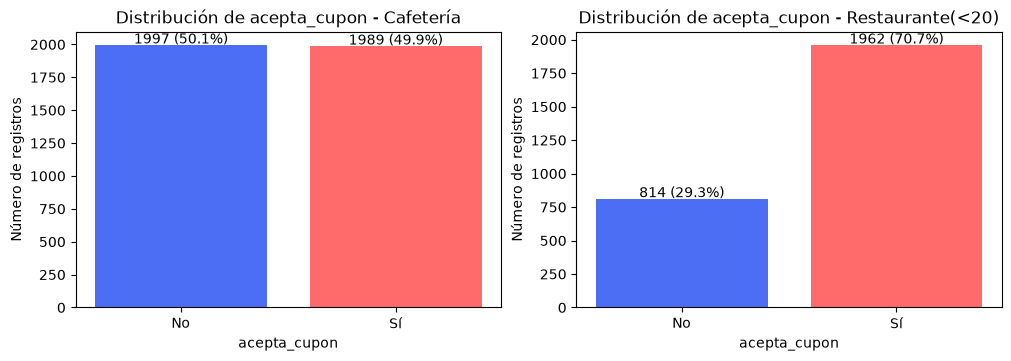

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)

for i, (nombre, df) in enumerate([('Cafetería', data_cafe), ('Restaurante(<20)', data_rest)]):
    conteo = df['acepta_cupon'].value_counts().sort_index()
    ax[i].bar(conteo.index, conteo.values, color=['#4C6EF5', '#FF6B6B'])
    for j, v in enumerate(conteo.values):
        ax[i].text(j, v + 10, f"{v} ({v/len(df)*100:.1f}%)", ha='center')
    ax[i].set(xlabel='acepta_cupon', ylabel='Número de registros', title=f'Distribución de acepta_cupon - {nombre}')

plt.show()

### 1.5 Tasa de aceptación según algunas variables

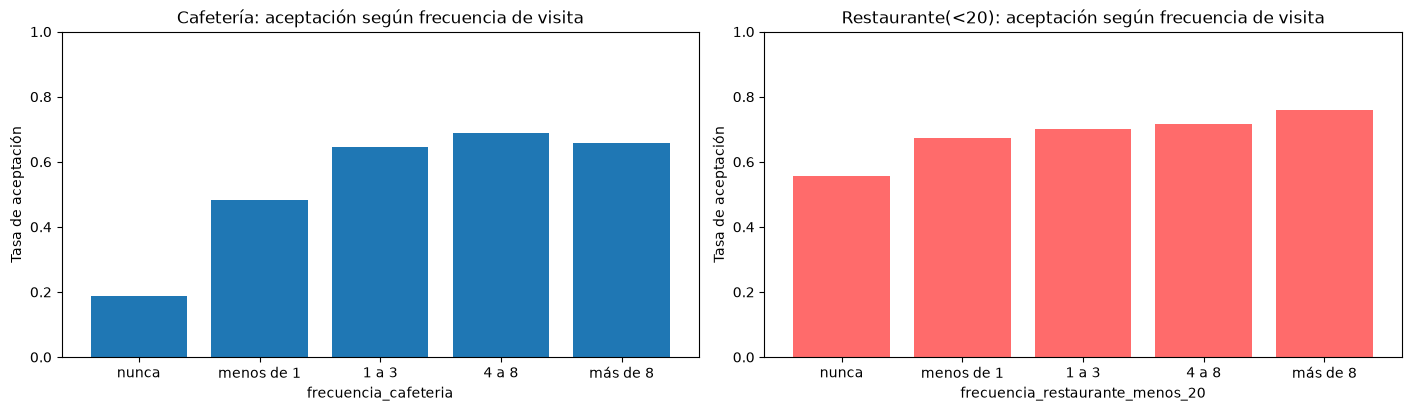

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

orden_frec = ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8']

tasa_cafe = (data_cafe['acepta_cupon'] == 'Sí').groupby(data_cafe['frecuencia_cafeteria']).mean().reindex(orden_frec)
ax[0].bar(tasa_cafe.index, tasa_cafe.values)
ax[0].set(xlabel='frecuencia_cafeteria', ylabel='Tasa de aceptación', title='Cafetería: aceptación según frecuencia de visita', ylim=(0, 1))

tasa_rest = (data_rest['acepta_cupon'] == 'Sí').groupby(data_rest['frecuencia_restaurante_menos_20']).mean().reindex(orden_frec)
ax[1].bar(tasa_rest.index, tasa_rest.values, color='#FF6B6B')
ax[1].set(xlabel='frecuencia_restaurante_menos_20', ylabel='Tasa de aceptación', title='Restaurante(<20): aceptación según frecuencia de visita', ylim=(0, 1))

plt.show()

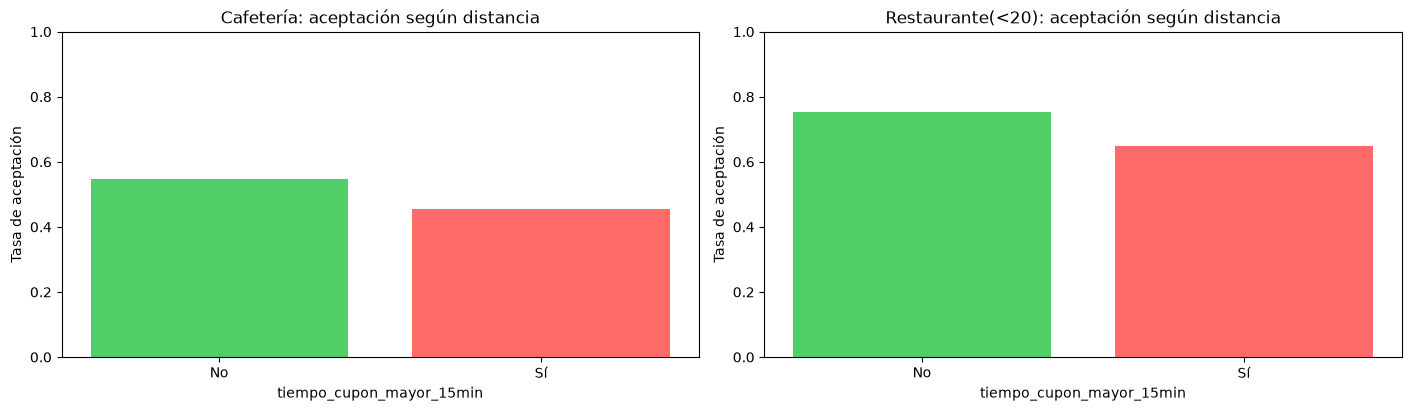

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

for i, (nombre, df) in enumerate([('Cafetería', data_cafe), ('Restaurante(<20)', data_rest)]):
    tasa = (df['acepta_cupon'] == 'Sí').groupby(df['tiempo_cupon_mayor_15min']).mean()
    ax[i].bar(tasa.index, tasa.values, color=['#51CF66', '#FF6B6B'])
    ax[i].set(xlabel='tiempo_cupon_mayor_15min', ylabel='Tasa de aceptación', title=f'{nombre}: aceptación según distancia', ylim=(0, 1))

plt.show()

### Hallazgos de la exploración

- **Tamaño:** Cafetería tiene 3.986 registros y Restaurante(<20) 2.776. Todas las variables son categóricas excepto `temperatura`, que solo toma 3 valores.
- **Nulos:** `vehiculo` está vacía en cerca del 99% de los registros, así que no aporta información. Las columnas `frecuencia_*` tienen pocos nulos (menos del 2%).
- **Duplicados:** hay 7 filas exactamente iguales en cada subconjunto.
- **Variables constantes o redundantes:**
  - `tiempo_cupon_mayor_5min` vale siempre "Sí", así que no aporta nada.
  - `direccion_opuesta` es exactamente el complemento de `misma_direccion`.
  - `temperatura` depende en buena parte del `clima`, pero no del todo (con clima soleado toma las 3 temperaturas), así que se conserva.
- **Variable objetivo:**
  - **Cafetería** está balanceada (≈50% / 50%).
  - **Restaurante(<20)** está desbalanceada: ≈71% "Sí" y ≈29% "No", así que la clase minoritaria es **"No"**. Esto justifica evaluar el balanceo de clases en el punto 6.
- La aceptación crece con la frecuencia de visita al tipo de establecimiento y baja cuando el lugar queda a más de 15 minutos, así que es de esperar que estas variables sean relevantes.

## 2. Limpieza y preparación de los datos

| Problema | Decisión | Justificación |
|---|---|---|
| `vehiculo` ≈99% nula | Eliminar columna | Imputar casi el 100% de una columna inventaría información. |
| `tiempo_cupon_mayor_5min` constante | Eliminar columna | No tiene varianza, así que no ayuda a separar clases. |
| `direccion_opuesta` = complemento de `misma_direccion` | Eliminar columna | Es redundante (multicolinealidad perfecta en la regresión logística). |
| `cupon` constante dentro de cada subconjunto | Eliminar columna | Ya se filtró por tipo de cupón. |
| Registros duplicados | Eliminar (`drop_duplicates`) | Evita que un mismo ejemplo quede en train y en test. |
| Nulos en `frecuencia_*` (<2%) | Imputar con la **moda** (`SimpleImputer`) dentro del pipeline | Son pocos y categóricos. Hacerlo dentro del pipeline evita fuga de información. |
| Variables ordinales (`hora`, `edad`, `educacion`, `ingreso`, `frecuencia_*`) | `OrdinalEncoder` con el orden del diccionario | Se conserva el orden natural de las categorías. |
| Variables nominales | `OneHotEncoder(drop='if_binary')` | No tienen orden. |
| Escala | `StandardScaler` | Necesario para la regresión logística regularizada. No afecta a los árboles. |
| `acepta_cupon` | Sí → 1, No → 0 | Variable objetivo binaria. |

La eliminación de columnas se hace con un `FunctionTransformer` dentro del pipeline, igual que en la práctica de regresión logística. Así el mismo pipeline sirve directamente para el archivo de prueba.

In [20]:
# Eliminar duplicados en cada subconjunto
data_cafe = data_cafe.drop_duplicates().reset_index(drop=True)
data_rest = data_rest.drop_duplicates().reset_index(drop=True)

# Variable objetivo binaria
data_cafe['acepta_cupon'] = np.where(data_cafe['acepta_cupon'] == 'Sí', 1, 0)
data_rest['acepta_cupon'] = np.where(data_rest['acepta_cupon'] == 'Sí', 1, 0)

print(f"Cafetería:        {data_cafe.shape}")
print(f"Restaurante(<20): {data_rest.shape}")

Cafetería:        (3979, 26)
Restaurante(<20): (2769, 26)


In [21]:
cols_to_drop = ['vehiculo', 'tiempo_cupon_mayor_5min', 'direccion_opuesta', 'cupon']

def drop_columns(df):
    return df.drop(columns=cols_to_drop, errors="ignore")

dropper = FunctionTransformer(drop_columns)

In [22]:
orden_frec = ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8']

ordinales_features = {
    'hora': ['7:00 a.m.', '10:00 a.m.', '2:00 p.m.', '6:00 p.m.', '10:00 p.m.'],
    'edad': ['menor de 21', '21', '26', '31', '36', '41', '46', '50 o más'],
    'educacion': ['Bachillerato incompleto', 'Bachillerato completo', 'Estudios universitarios sin título',
                  'Técnico/Tecnólogo', 'Pregrado', 'Posgrado (Maestría o Doctorado)'],
    'ingreso': ['Menos de $12.500', '$12.500 - $24.999', '$25.000 - $37.499', '$37.500 - $49.999',
                '$50.000 - $62.499', '$62.500 - $74.999', '$75.000 - $87.499', '$87.500 - $99.999', '$100.000 o más'],
    'frecuencia_bar': orden_frec,
    'frecuencia_cafeteria': orden_frec,
    'frecuencia_comida_para_llevar': orden_frec,
    'frecuencia_restaurante_menos_20': orden_frec,
    'frecuencia_restaurante_20_a_50': orden_frec,
}

numericas_features = ['temperatura']
ordinales_cols = list(ordinales_features.keys())
categoricas_features = ['destino', 'acompanante', 'clima', 'vigencia_cupon', 'genero', 'estado_civil',
                        'tiene_hijos', 'ocupacion', 'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min',
                        'misma_direccion']

In [23]:
numerica_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

ordinal_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=list(ordinales_features.values()))),
    ('scaler', StandardScaler())
])

categorica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='if_binary'))
])

preprocesador = ColumnTransformer(
    transformers=[
        ('num', numerica_transformer, numericas_features),
        ('ord', ordinal_transformer, ordinales_cols),
        ('cat', categorica_transformer, categoricas_features)
    ]
)

### División en entrenamiento y prueba

Se usa una partición 80/20 **estratificada** para cada tipo de cupón y validación cruzada estratificada de 5 folds para la búsqueda de hiperparámetros. La métrica de selección es **F1-macro**, porque pondera por igual las dos clases (importante en Restaurante(<20), que está desbalanceado).

In [24]:
X_cafe = data_cafe.drop(columns=['acepta_cupon'])
y_cafe = data_cafe['acepta_cupon']
X_train_cafe, X_test_cafe, y_train_cafe, y_test_cafe = train_test_split(
    X_cafe, y_cafe, test_size=0.2, random_state=42, stratify=y_cafe)

X_rest = data_rest.drop(columns=['acepta_cupon'])
y_rest = data_rest['acepta_cupon']
X_train_rest, X_test_rest, y_train_rest, y_test_rest = train_test_split(
    X_rest, y_rest, test_size=0.2, random_state=42, stratify=y_rest)

print(f"Cafetería        -> train: {X_train_cafe.shape}, test: {X_test_cafe.shape}")
print(f"Restaurante(<20) -> train: {X_train_rest.shape}, test: {X_test_rest.shape}")

Cafetería        -> train: (3183, 25), test: (796, 25)
Restaurante(<20) -> train: (2215, 25), test: (554, 25)


In [25]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 3. Regresión logística

Se exploran el tipo de regularización (`penalty`), el `solver` y la fuerza de regularización `C`, usando solo combinaciones válidas de penalty y solver.

In [26]:
pipeline_rl = Pipeline(steps=[
    ('dropper', dropper),
    ('preprocesador', preprocesador),
    ('modelo', LogisticRegression(max_iter=1000))
])

param_grid_rl = [
    # Combinaciones válidas con L2
    {
        'modelo__penalty': ['l2'],
        'modelo__solver': ['newton-cg', 'lbfgs', 'liblinear'],
        'modelo__C': [0.01, 0.1, 0.5, 1]
    },
    # Combinaciones válidas con L1
    {
        'modelo__penalty': ['l1'],
        'modelo__solver': ['liblinear', 'saga'],
        'modelo__C': [0.01, 0.1, 0.5, 1]
    }
]

### 3.1 Cafetería

In [27]:
grid_rl_cafe = GridSearchCV(estimator=pipeline_rl, param_grid=param_grid_rl, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_rl_cafe.fit(X_train_cafe, y_train_cafe)

print("Mejores hiperparámetros:", grid_rl_cafe.best_params_)
print(f"F1-macro en validación cruzada: {grid_rl_cafe.best_score_:.3f}")

best_rl_cafe = grid_rl_cafe.best_estimator_

Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}
F1-macro en validación cruzada: 0.711


In [28]:
y_pred_rl_cafe = best_rl_cafe.predict(X_test_cafe)
print(classification_report(y_test_cafe, y_pred_rl_cafe, target_names=['No', 'Sí']))

              precision    recall  f1-score   support

          No       0.69      0.68      0.69       399
          Sí       0.69      0.70      0.69       397

    accuracy                           0.69       796
   macro avg       0.69      0.69      0.69       796
weighted avg       0.69      0.69      0.69       796



### 3.2 Restaurante(<20)

In [29]:
grid_rl_rest = GridSearchCV(estimator=pipeline_rl, param_grid=param_grid_rl, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_rl_rest.fit(X_train_rest, y_train_rest)

print("Mejores hiperparámetros:", grid_rl_rest.best_params_)
print(f"F1-macro en validación cruzada: {grid_rl_rest.best_score_:.3f}")

best_rl_rest = grid_rl_rest.best_estimator_

Mejores hiperparámetros: {'modelo__C': 1, 'modelo__penalty': 'l2', 'modelo__solver': 'newton-cg'}
F1-macro en validación cruzada: 0.658


In [30]:
y_pred_rl_rest = best_rl_rest.predict(X_test_rest)
print(classification_report(y_test_rest, y_pred_rl_rest, target_names=['No', 'Sí']))

              precision    recall  f1-score   support

          No       0.60      0.38      0.46       162
          Sí       0.78      0.90      0.83       392

    accuracy                           0.75       554
   macro avg       0.69      0.64      0.65       554
weighted avg       0.73      0.75      0.73       554



## 4. Árboles de decisión

Se exploran la profundidad máxima (`max_depth`), el número mínimo de muestras por hoja (`min_samples_leaf`) y el criterio de división (`criterion`).

In [31]:
pipeline_dt = Pipeline(steps=[
    ('dropper', dropper),
    ('preprocesador', preprocesador),
    ('modelo', DecisionTreeClassifier(random_state=42))
])

param_grid_dt = {
    'modelo__criterion': ['gini', 'entropy', 'log_loss'],
    'modelo__max_depth': [3, 5, 7, 10, 15],
    'modelo__min_samples_leaf': [1, 5, 10, 20]
}

### 4.1 Cafetería

In [32]:
grid_dt_cafe = GridSearchCV(estimator=pipeline_dt, param_grid=param_grid_dt, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_dt_cafe.fit(X_train_cafe, y_train_cafe)

print("Mejores hiperparámetros:", grid_dt_cafe.best_params_)
print(f"F1-macro en validación cruzada: {grid_dt_cafe.best_score_:.3f}")

best_dt_cafe = grid_dt_cafe.best_estimator_

Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5}
F1-macro en validación cruzada: 0.709


In [33]:
y_pred_dt_cafe = best_dt_cafe.predict(X_test_cafe)
print(classification_report(y_test_cafe, y_pred_dt_cafe, target_names=['No', 'Sí']))

              precision    recall  f1-score   support

          No       0.70      0.66      0.68       399
          Sí       0.68      0.71      0.69       397

    accuracy                           0.69       796
   macro avg       0.69      0.69      0.69       796
weighted avg       0.69      0.69      0.69       796



### 4.2 Restaurante(<20)

In [34]:
grid_dt_rest = GridSearchCV(estimator=pipeline_dt, param_grid=param_grid_dt, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_dt_rest.fit(X_train_rest, y_train_rest)

print("Mejores hiperparámetros:", grid_dt_rest.best_params_)
print(f"F1-macro en validación cruzada: {grid_dt_rest.best_score_:.3f}")

best_dt_rest = grid_dt_rest.best_estimator_

Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 20}
F1-macro en validación cruzada: 0.686


In [35]:
y_pred_dt_rest = best_dt_rest.predict(X_test_rest)
print(classification_report(y_test_rest, y_pred_dt_rest, target_names=['No', 'Sí']))

              precision    recall  f1-score   support

          No       0.64      0.39      0.48       162
          Sí       0.78      0.91      0.84       392

    accuracy                           0.76       554
   macro avg       0.71      0.65      0.66       554
weighted avg       0.74      0.76      0.74       554



## 5. Random Forest

Se exploran el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el número mínimo de muestras por hoja (`min_samples_leaf`).

In [36]:
pipeline_rf = Pipeline(steps=[
    ('dropper', dropper),
    ('preprocesador', preprocesador),
    ('modelo', RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    'modelo__n_estimators': [100, 200, 300],
    'modelo__max_depth': [6, 10, 15],
    'modelo__min_samples_leaf': [1, 3, 5]
}

### 5.1 Cafetería

In [37]:
grid_rf_cafe = GridSearchCV(estimator=pipeline_rf, param_grid=param_grid_rf, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_rf_cafe.fit(X_train_cafe, y_train_cafe)

print("Mejores hiperparámetros:", grid_rf_cafe.best_params_)
print(f"F1-macro en validación cruzada: {grid_rf_cafe.best_score_:.3f}")

best_rf_cafe = grid_rf_cafe.best_estimator_

Mejores hiperparámetros: {'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 300}
F1-macro en validación cruzada: 0.761


In [38]:
y_pred_rf_cafe = best_rf_cafe.predict(X_test_cafe)
print(classification_report(y_test_cafe, y_pred_rf_cafe, target_names=['No', 'Sí']))

              precision    recall  f1-score   support

          No       0.78      0.76      0.77       399
          Sí       0.77      0.78      0.77       397

    accuracy                           0.77       796
   macro avg       0.77      0.77      0.77       796
weighted avg       0.77      0.77      0.77       796



### 5.2 Restaurante(<20)

In [39]:
grid_rf_rest = GridSearchCV(estimator=pipeline_rf, param_grid=param_grid_rf, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_rf_rest.fit(X_train_rest, y_train_rest)

print("Mejores hiperparámetros:", grid_rf_rest.best_params_)
print(f"F1-macro en validación cruzada: {grid_rf_rest.best_score_:.3f}")

best_rf_rest = grid_rf_rest.best_estimator_

Mejores hiperparámetros: {'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1-macro en validación cruzada: 0.695


In [40]:
y_pred_rf_rest = best_rf_rest.predict(X_test_rest)
print(classification_report(y_test_rest, y_pred_rf_rest, target_names=['No', 'Sí']))

              precision    recall  f1-score   support

          No       0.71      0.40      0.51       162
          Sí       0.79      0.93      0.86       392

    accuracy                           0.78       554
   macro avg       0.75      0.66      0.68       554
weighted avg       0.77      0.78      0.75       554



## 6. Balanceo de clases con SMOTE en Restaurante(<20)

En Restaurante(<20) la clase minoritaria es **"No" (0)**, con ≈29%. Se aplica SMOTE dentro de un pipeline de `imblearn`, igual que en la práctica de KNN y SMOTE. Así el sobremuestreo solo ocurre en los folds de entrenamiento y nunca en validación ni en test. Se repite la búsqueda de hiperparámetros con las mismas grillas para los tres algoritmos y se compara cada uno con su versión sin balancear.

*Nota:* SMOTE se aplica después del preprocesamiento, sobre variables ya codificadas. Por eso algunos ejemplos sintéticos pueden tener valores intermedios entre categorías.

In [41]:
def pipeline_smote(modelo):
    return ImbPipeline(steps=[
        ('dropper', dropper),
        ('preprocesador', preprocesador),
        ('smote', SMOTE(random_state=42)),
        ('modelo', modelo)
    ])

grid_rl_smote = GridSearchCV(estimator=pipeline_smote(LogisticRegression(max_iter=1000)),
                             param_grid=param_grid_rl, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_dt_smote = GridSearchCV(estimator=pipeline_smote(DecisionTreeClassifier(random_state=42)),
                             param_grid=param_grid_dt, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_rf_smote = GridSearchCV(estimator=pipeline_smote(RandomForestClassifier(random_state=42)),
                             param_grid=param_grid_rf, cv=kfold, scoring='f1_macro', n_jobs=-1)

for nombre, grid in [('Regresión logística', grid_rl_smote), ('Árbol de decisión', grid_dt_smote), ('Random Forest', grid_rf_smote)]:
    grid.fit(X_train_rest, y_train_rest)
    print(f"{nombre} + SMOTE")
    print("  Mejores hiperparámetros:", grid.best_params_)
    print(f"  F1-macro en validación cruzada: {grid.best_score_:.3f}")

best_rl_smote = grid_rl_smote.best_estimator_
best_dt_smote = grid_dt_smote.best_estimator_
best_rf_smote = grid_rf_smote.best_estimator_

Regresión logística + SMOTE
  Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'newton-cg'}
  F1-macro en validación cruzada: 0.671


Árbol de decisión + SMOTE
  Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 20}
  F1-macro en validación cruzada: 0.664


Random Forest + SMOTE
  Mejores hiperparámetros: {'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
  F1-macro en validación cruzada: 0.705


In [42]:
y_pred_rl_smote = best_rl_smote.predict(X_test_rest)
y_pred_dt_smote = best_dt_smote.predict(X_test_rest)
y_pred_rf_smote = best_rf_smote.predict(X_test_rest)

In [43]:
def metricas_smote(y_true, y_pred):
    return {
        'F1-macro': f1_score(y_true, y_pred, average='macro'),
        'F1 (No)': f1_score(y_true, y_pred, pos_label=0),
        'Recall (No)': recall_score(y_true, y_pred, pos_label=0),
        'Precisión (No)': precision_score(y_true, y_pred, pos_label=0, zero_division=0),
    }

resultados_smote = pd.DataFrame({
    'RL (sin SMOTE)': metricas_smote(y_test_rest, y_pred_rl_rest),
    'RL + SMOTE': metricas_smote(y_test_rest, y_pred_rl_smote),
    'Árbol (sin SMOTE)': metricas_smote(y_test_rest, y_pred_dt_rest),
    'Árbol + SMOTE': metricas_smote(y_test_rest, y_pred_dt_smote),
    'RF (sin SMOTE)': metricas_smote(y_test_rest, y_pred_rf_rest),
    'RF + SMOTE': metricas_smote(y_test_rest, y_pred_rf_smote),
}).T

display(resultados_smote.round(3))

,F1-macro,F1 (No),Recall (No),Precisión (No)
RL (sin SMOTE),0.649,0.464,0.377,0.604
RL + SMOTE,0.668,0.552,0.617,0.500
Árbol (sin SMOTE),0.663,0.485,0.389,0.643
Árbol + SMOTE,0.655,0.541,0.617,0.481
RF (sin SMOTE),0.682,0.508,0.395,0.711
RF + SMOTE,0.683,0.524,0.444,0.637


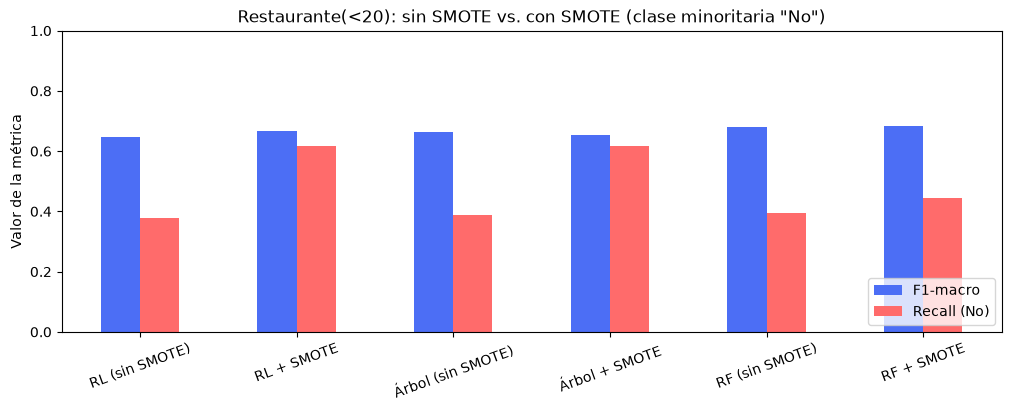

In [44]:
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
resultados_smote[['F1-macro', 'Recall (No)']].plot(kind='bar', ax=ax, color=['#4C6EF5', '#FF6B6B'])
ax.set(ylabel='Valor de la métrica', title='Restaurante(<20): sin SMOTE vs. con SMOTE (clase minoritaria "No")', ylim=(0, 1))
ax.legend(loc='lower right')
plt.xticks(rotation=20)
plt.show()

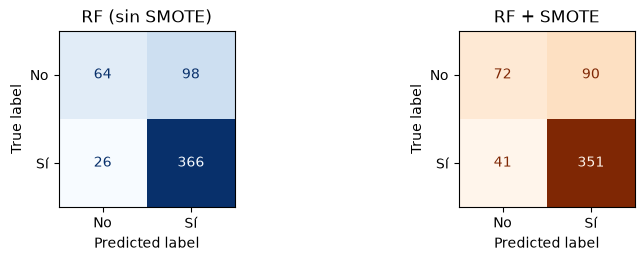

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(8, 2.5), constrained_layout=True)

ConfusionMatrixDisplay.from_predictions(
    y_test_rest, y_pred_rf_rest, display_labels=['No', 'Sí'], cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('RF (sin SMOTE)')

ConfusionMatrixDisplay.from_predictions(
    y_test_rest, y_pred_rf_smote, display_labels=['No', 'Sí'], cmap='Oranges', ax=axes[1], colorbar=False
)
axes[1].set_title('RF + SMOTE')

plt.show()

### Conclusión del balanceo

- **Sin balancear**, los tres modelos tienen un recall muy bajo para la clase minoritaria "No" (≈0,38–0,40). Es decir, detectan menos de la mitad de los conductores que rechazan el cupón, porque tienden a predecir "Sí", la clase mayoritaria.
- **Con SMOTE**, el recall de "No" sube en los tres algoritmos:
  - Regresión logística: 0,377 → 0,617
  - Árbol de decisión: 0,389 → 0,617
  - Random Forest: 0,395 → 0,444

  A cambio baja la precisión de "No", porque el modelo predice "No" con más frecuencia.
- **Efecto en el F1-macro:**
  - Mejora en la regresión logística (0,649 → 0,668).
  - Se mantiene prácticamente igual en Random Forest (0,682 → 0,683).
  - Baja un poco en el árbol (0,663 → 0,655).

**Recomendación:** sí conviene aplicar SMOTE en Restaurante(<20). Con el mismo o mejor F1 general, el modelo identifica mejor a los conductores que **no** van a aceptar el cupón. Esto es justamente lo que permite evitar notificaciones irrelevantes, que es una de las molestias que quiere reducir Ruta Alpes. El modelo recomendado es **Random Forest + SMOTE**, que tiene el mejor F1-macro de todos los modelos de Restaurante(<20). Si el objetivo de negocio fuera maximizar la detección de rechazos, la regresión logística + SMOTE ofrece un recall de "No" bastante mayor (0,617), a costa de más falsos "No".

## 7. Tabla comparativa sobre test

Para cada modelo se reportan precisión, recall y F1 de la clase positiva (**acepta = Sí**) y el F1-macro, que fue la métrica de selección en validación cruzada.

In [46]:
def metricas_modelo(y_true, y_pred):
    return {
        'Precisión (Sí)': precision_score(y_true, y_pred, pos_label=1),
        'Recall (Sí)': recall_score(y_true, y_pred, pos_label=1),
        'F1 (Sí)': f1_score(y_true, y_pred, pos_label=1),
        'F1-macro': f1_score(y_true, y_pred, average='macro'),
    }

tabla_cafe = pd.DataFrame({
    'Regresión logística': metricas_modelo(y_test_cafe, y_pred_rl_cafe),
    'Árbol de decisión': metricas_modelo(y_test_cafe, y_pred_dt_cafe),
    'Random Forest': metricas_modelo(y_test_cafe, y_pred_rf_cafe),
}).T

tabla_rest = pd.DataFrame({
    'Regresión logística': metricas_modelo(y_test_rest, y_pred_rl_rest),
    'Árbol de decisión': metricas_modelo(y_test_rest, y_pred_dt_rest),
    'Random Forest': metricas_modelo(y_test_rest, y_pred_rf_rest),
    'Regresión logística + SMOTE': metricas_modelo(y_test_rest, y_pred_rl_smote),
    'Árbol de decisión + SMOTE': metricas_modelo(y_test_rest, y_pred_dt_smote),
    'Random Forest + SMOTE': metricas_modelo(y_test_rest, y_pred_rf_smote),
}).T

tabla_comparativa = pd.concat({'Cafetería': tabla_cafe, 'Restaurante(<20)': tabla_rest})
display(tabla_comparativa.round(3))

Precisión (Sí)  Recall (Sí)  \
Cafetería        Regresión logística                   0.687        0.695   
                 Árbol de decisión                     0.677        0.708   
                 Random Forest                         0.765        0.781   
Restaurante(<20) Regresión logística                   0.777        0.898   
                 Árbol de decisión                     0.783        0.911   
                 Random Forest                         0.789        0.934   
                 Regresión logística + SMOTE           0.825        0.745   
                 Árbol de decisión + SMOTE             0.821        0.724   
                 Random Forest + SMOTE                 0.796        0.895   

                                              F1 (Sí)  F1-macro  
Cafetería        Regresión logística            0.691     0.690  
                 Árbol de decisión              0.692     0.686  
                 Random Forest                  0.773     0.771  
Restaurante(<20) Regresión logística            0.833     0.649  
                 Árbol de decisión              0.842     0.663  
                 Random Forest                  0.855     0.682  
                 Regresión logística + SMOTE    0.783     0.668  
                 Árbol de decisión + SMOTE      0.770     0.655  
                 Random Forest + SMOTE          0.843     0.683

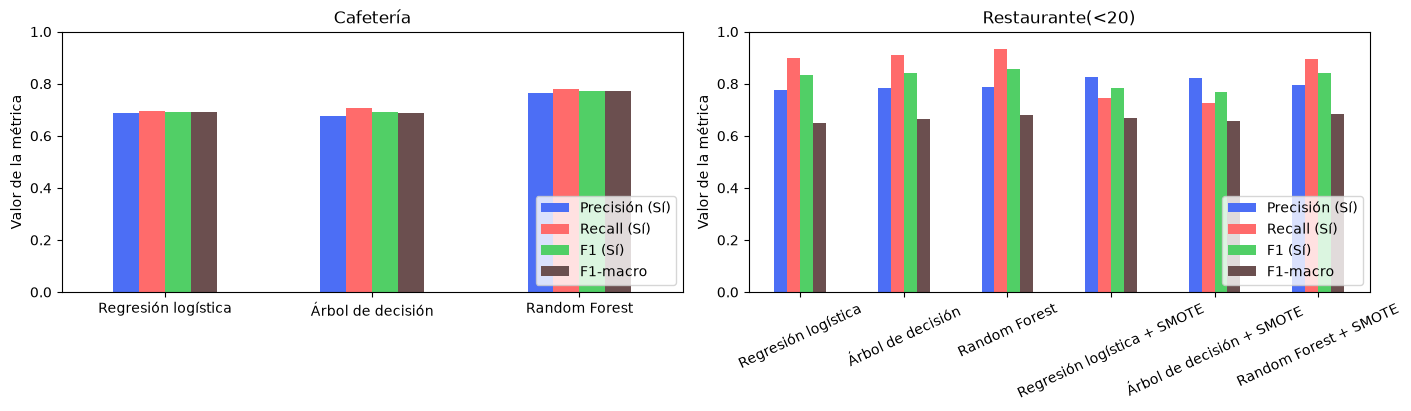

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

tabla_cafe.plot(kind='bar', ax=ax[0], color=['#4C6EF5', '#FF6B6B', '#51CF66', '#6b4f4f'])
ax[0].set(ylabel='Valor de la métrica', title='Cafetería', ylim=(0, 1))
ax[0].legend(loc='lower right')
ax[0].tick_params(axis='x', rotation=0)

tabla_rest.plot(kind='bar', ax=ax[1], color=['#4C6EF5', '#FF6B6B', '#51CF66', '#6b4f4f'])
ax[1].set(ylabel='Valor de la métrica', title='Restaurante(<20)', ylim=(0, 1))
ax[1].legend(loc='lower right')
ax[1].tick_params(axis='x', rotation=25)

plt.show()

In [48]:
# Selección del mejor modelo por tipo de cupón según F1-macro en test
modelos_cafe = {
    'Regresión logística': best_rl_cafe,
    'Árbol de decisión': best_dt_cafe,
    'Random Forest': best_rf_cafe,
}
modelos_rest = {
    'Regresión logística': best_rl_rest,
    'Árbol de decisión': best_dt_rest,
    'Random Forest': best_rf_rest,
    'Regresión logística + SMOTE': best_rl_smote,
    'Árbol de decisión + SMOTE': best_dt_smote,
    'Random Forest + SMOTE': best_rf_smote,
}

nombre_mejor_cafe = tabla_cafe['F1-macro'].idxmax()
nombre_mejor_rest = tabla_rest['F1-macro'].idxmax()

mejor_modelo_cafe = modelos_cafe[nombre_mejor_cafe]
mejor_modelo_rest = modelos_rest[nombre_mejor_rest]

print(f"Mejor modelo Cafetería:        {nombre_mejor_cafe} (F1-macro = {tabla_cafe.loc[nombre_mejor_cafe, 'F1-macro']:.3f})")
print(f"Mejor modelo Restaurante(<20): {nombre_mejor_rest} (F1-macro = {tabla_rest.loc[nombre_mejor_rest, 'F1-macro']:.3f})")

Mejor modelo Cafetería:        Random Forest (F1-macro = 0.771)
Mejor modelo Restaurante(<20): Random Forest + SMOTE (F1-macro = 0.683)


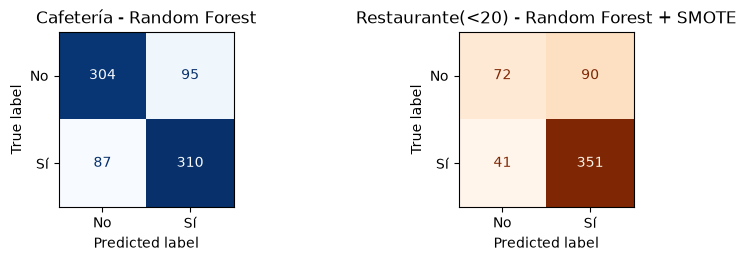

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(8, 2.5), constrained_layout=True)

ConfusionMatrixDisplay.from_estimator(
    mejor_modelo_cafe, X_test_cafe, y_test_cafe, display_labels=['No', 'Sí'], cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title(f'Cafetería - {nombre_mejor_cafe}')

ConfusionMatrixDisplay.from_estimator(
    mejor_modelo_rest, X_test_rest, y_test_rest, display_labels=['No', 'Sí'], cmap='Oranges', ax=axes[1], colorbar=False
)
axes[1].set_title(f'Restaurante(<20) - {nombre_mejor_rest}')

plt.show()

### Selección del mejor modelo

- **Cafetería:** Random Forest es claramente el mejor modelo, con F1-macro de 0,771 y F1 (Sí) de 0,773, frente a ≈0,69 de la regresión logística y del árbol. Como la clase está balanceada, la precisión y el recall son parecidos entre sí. El ensamble de árboles captura interacciones entre variables (por ejemplo, frecuencia de visita × hora × acompañante) que un modelo lineal o un solo árbol poco profundo no logran.
- **Restaurante(<20):** todos los modelos tienen F1 (Sí) alto (≈0,83–0,86), pero esto se debe en parte al desbalance, porque predecir "Sí" casi siempre ya da un buen F1 para esa clase. Por eso la selección se hace con el **F1-macro**, que penaliza ignorar la clase "No". El mejor es **Random Forest + SMOTE** (0,683), casi empatado con Random Forest sin balancear (0,682), pero con mejor recall de la clase minoritaria (ver punto 6).
- En general, el desempeño es menor en Restaurante(<20) que en Cafetería, debido al desbalance de clases y a que hay menos datos (2.769 frente a 3.979 registros).

**Modelos seleccionados para las predicciones:**
- Cafetería → **Random Forest** (`max_depth=15`, `min_samples_leaf=1`, `n_estimators=300`).
- Restaurante(<20) → **Random Forest + SMOTE** (`max_depth=15`, `min_samples_leaf=1`, `n_estimators=200`).

## Predicciones sobre los datos de prueba (`Lab3_datos_Prueba`)

Cada registro del archivo de prueba se predice con el mejor modelo de su tipo de cupón. Los pipelines ya incluyen la eliminación de columnas, la imputación y la codificación, así que se les pasan los datos tal como vienen. La predicción se agrega en la columna `acepta_cupon` (Sí/No) y el resultado se exporta a CSV con la misma estructura del archivo original.

In [50]:
datos_prueba = pd.read_excel('./Data/Lab3_datos_Prueba.xlsx')
prueba = datos_prueba.copy()

print(prueba.shape)
prueba['cupon'].value_counts()

(20, 25)


cupon
Cafetería           10
Restaurante(<20)    10
Name: count, dtype: int64

In [51]:
es_cafe = prueba['cupon'] == 'Cafetería'
es_rest = prueba['cupon'] == 'Restaurante(<20)'

prueba.loc[es_cafe, 'acepta_cupon'] = mejor_modelo_cafe.predict(prueba[es_cafe])
prueba.loc[es_rest, 'acepta_cupon'] = mejor_modelo_rest.predict(prueba[es_rest])

prueba['acepta_cupon'] = np.where(prueba['acepta_cupon'] == 1, 'Sí', 'No')

prueba[['cupon', 'acepta_cupon']].value_counts().sort_index()

cupon             acepta_cupon
Cafetería         No              4
                  Sí              6
Restaurante(<20)  No              1
                  Sí              9
Name: count, dtype: int64

In [52]:
prueba.to_csv('Lab3_datos_Prueba.csv', index=False, encoding='utf-8-sig')
prueba.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Trabajo,Solo,Soleado,55,7:00 a.m.,Cafetería,2 horas,Femenino,50 o más,Divorciado(a),...,4 a 8,4 a 8,4 a 8,menos de 1,Sí,Sí,No,No,Sí,No
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,31,Unión libre,...,1 a 3,más de 8,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
2,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,31,Soltero(a),...,1 a 3,4 a 8,más de 8,menos de 1,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Pareja,Soleado,80,10:00 a.m.,Cafetería,2 horas,Masculino,50 o más,Casado(a),...,más de 8,nunca,4 a 8,menos de 1,Sí,No,No,No,Sí,Sí
4,Sin lugar urgente,Amigo(s),Soleado,80,6:00 p.m.,Restaurante(<20),2 horas,Femenino,26,Soltero(a),...,menos de 1,4 a 8,menos de 1,4 a 8,Sí,Sí,No,No,Sí,Sí
